<a href="https://colab.research.google.com/github/rrafikb/wti-inventory-carry-backtest/blob/main/wti_inventory_carry_backtest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/tmp/ipykernel_15865/2309033919.py:31: FutureWarning: YF.download() has changed argument auto_adjust default to True
  wti = yf.download('CL=F', start='2005-01-01', progress=False)['Close'].squeeze()


            stocks  imports  exports  refinery
period                                        
2026-10-09  415577   6049.0   4570.0     16615
2026-10-16  412517   5758.0   3442.0     16649
2026-10-23  410625   6374.0   4854.0     16526
2026-10-30  409760   6374.0   3675.0     16725
2026-11-06  414417   6698.0   3455.0     17047
1140 weeks of EIA data, 5501 days of WTI prices


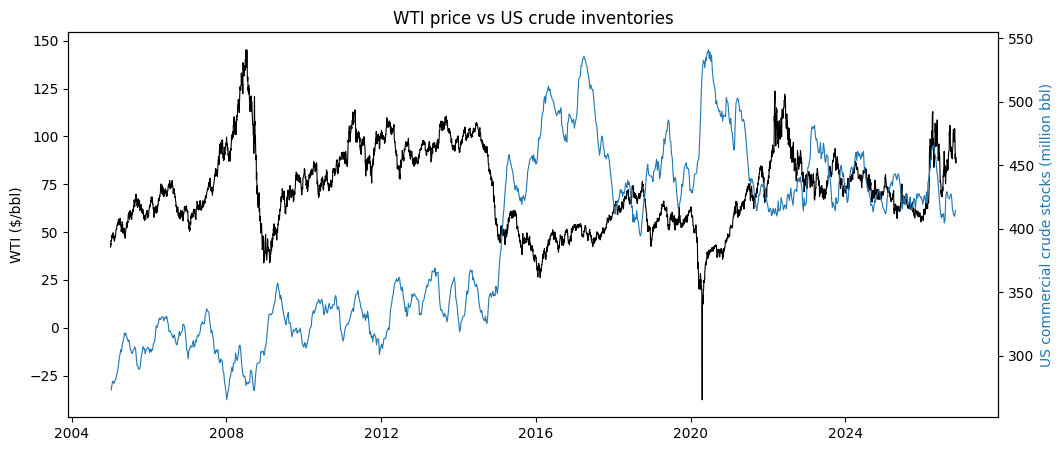

            mean  count
bucket                 
Big draw   0.555    125
Draw      -0.391    124
Normal     0.587    125
Build     -0.491    124
Big build  0.659    125

All weeks average: 0.186% per week


In [1]:
!pip install -q yfinance

import requests
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from google.colab import userdata

API_KEY = userdata.get('EIA_KEY')

# The four weekly EIA series we want
SERIES = {
    'stocks':   'WCESTUS1',  # US commercial crude stocks excl. SPR (thousand barrels)
    'imports':  'WCRIMUS2',  # crude imports (thousand barrels/day)
    'exports':  'WCREXUS2',  # crude exports (thousand barrels/day)
    'refinery': 'WCRRIUS2',  # refinery crude inputs (thousand barrels/day)
}

def get_eia(series_id):
    url = f'https://api.eia.gov/v2/seriesid/PET.{series_id}.W'
    r = requests.get(url, params={'api_key': API_KEY})
    r.raise_for_status()
    df = pd.DataFrame(r.json()['response']['data'])
    s = pd.Series(pd.to_numeric(df['value'], errors='coerce').values,
                  index=pd.to_datetime(df['period']))
    return s.sort_index()

eia = pd.DataFrame({name: get_eia(sid) for name, sid in SERIES.items()}).loc['2005':]

# WTI front-month futures, daily closes
wti = yf.download('CL=F', start='2005-01-01', progress=False)['Close'].squeeze()

print(eia.tail())
print(f'{len(eia)} weeks of EIA data, {len(wti)} days of WTI prices')

# Plot price vs inventories
fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(wti.index, wti, color='black', lw=0.8)
ax1.set_ylabel('WTI ($/bbl)')
ax2 = ax1.twinx()
ax2.plot(eia.index, eia['stocks'] / 1000, color='tab:blue', lw=0.8)
ax2.set_ylabel('US commercial crude stocks (million bbl)', color='tab:blue')
plt.title('WTI price vs US crude inventories')
plt.show()

import numpy as np

df = eia.copy()
df['change'] = df['stocks'].diff()   # weekly inventory change (thousand bbl); negative = draw
df['year'] = df.index.isocalendar().year.astype(int)
df['week'] = df.index.isocalendar().week.astype(int)

# Seasonal norm: average change in the same calendar week over the PREVIOUS 5 years only
pivot = df.pivot_table(index='year', columns='week', values='change')
norm = pivot.shift(1).rolling(5, min_periods=5).mean()
df['norm'] = [norm.at[y, w] if w in norm.columns else np.nan for y, w in zip(df['year'], df['week'])]
df['surprise'] = df['change'] - df['norm']   # negative = bigger draw than usual = bullish

# Data is released the Wednesday after the week-ending Friday
df['release'] = df.index + pd.Timedelta(days=5)

# Entry = first WTI close on/after release day; drop the negative-price day in April 2020
px = wti[wti > 0]
pos = px.index.searchsorted(df['release'])
df = df[pos < len(px)].copy()
pos = pos[pos < len(px)]
df['entry_date'] = px.index[pos]
df['entry_price'] = px.values[pos]
df['fwd_return'] = df['entry_price'].shift(-1) / df['entry_price'] - 1   # return over the next week

# First look: exploration period only (2005-2021)
explore = df.loc[:'2021'].dropna(subset=['surprise', 'fwd_return']).copy()
explore['bucket'] = pd.qcut(explore['surprise'], 5,
                            labels=['Big draw', 'Draw', 'Normal', 'Build', 'Big build'])
summary = explore.groupby('bucket', observed=True)['fwd_return'].agg(['mean', 'count'])
summary['mean'] = (summary['mean'] * 100).round(3)
print(summary)
print(f"\nAll weeks average: {explore['fwd_return'].mean()*100:.3f}% per week")


In [2]:
import numpy as np

df = eia.copy()
df['change'] = df['stocks'].diff()   # weekly inventory change (thousand bbl); negative = draw
df['year'] = df.index.isocalendar().year.astype(int)
df['week'] = df.index.isocalendar().week.astype(int)

# Seasonal norm: average change in the same calendar week over the PREVIOUS 5 years only
pivot = df.pivot_table(index='year', columns='week', values='change')
norm = pivot.shift(1).rolling(5, min_periods=5).mean()
df['norm'] = [norm.at[y, w] if w in norm.columns else np.nan for y, w in zip(df['year'], df['week'])]
df['surprise'] = df['change'] - df['norm']   # negative = bigger draw than usual = bullish

# Data is released the Wednesday after the week-ending Friday
df['release'] = df.index + pd.Timedelta(days=5)

# Entry = first WTI close on/after release day; drop the negative-price day in April 2020
px = wti[wti > 0]
pos = px.index.searchsorted(df['release'])
df = df[pos < len(px)].copy()
pos = pos[pos < len(px)]
df['entry_date'] = px.index[pos]
df['entry_price'] = px.values[pos]
df['fwd_return'] = df['entry_price'].shift(-1) / df['entry_price'] - 1   # return over the next week

# First look: exploration period only (2005-2021)
explore = df.loc[:'2021'].dropna(subset=['surprise', 'fwd_return']).copy()
explore['bucket'] = pd.qcut(explore['surprise'], 5,
                            labels=['Big draw', 'Draw', 'Normal', 'Build', 'Big build'])
summary = explore.groupby('bucket', observed=True)['fwd_return'].agg(['mean', 'count'])
summary['mean'] = (summary['mean'] * 100).round(3)
print(summary)
print(f"\nAll weeks average: {explore['fwd_return'].mean()*100:.3f}% per week")


            mean  count
bucket                 
Big draw   0.555    125
Draw      -0.391    124
Normal     0.587    125
Build     -0.491    124
Big build  0.659    125

All weeks average: 0.186% per week


Test 1: Inventory surprise → next-week WTI return, 2010–2021. Result: no relationship.


In [3]:
# Close on the last trading day BEFORE release (usually Tuesday)
pos = px.index.searchsorted(df['release'])
df['prev_price'] = px.values[pos - 1]
df['release_day_return'] = df['entry_price'] / df['prev_price'] - 1

exp = df.loc['2010':'2021'].dropna(subset=['surprise', 'fwd_return', 'release_day_return']).copy()
exp['bucket'] = pd.qcut(exp['surprise'], 5,
                        labels=['Big draw', 'Draw', 'Normal', 'Build', 'Big build'])

table = exp.groupby('bucket', observed=True)[['release_day_return', 'fwd_return']].mean() * 100
print(table.round(3))
print(f"\nCorrelation, surprise vs release-day return: {exp['surprise'].corr(exp['release_day_return']):.3f}")
print(f"Correlation, surprise vs next-week return:   {exp['surprise'].corr(exp['fwd_return']):.3f}")

           release_day_return  fwd_return
bucket                                   
Big draw                0.645       0.555
Draw                    0.477      -0.391
Normal                  0.094       0.587
Build                  -0.140      -0.491
Big build              -0.197       0.659

Correlation, surprise vs release-day return: -0.088
Correlation, surprise vs next-week return:   -0.018


Test 2: Inventory surprise → release-day return (Tue close → Wed close), 2010–2021. Result: clear monotonic effect, correlation −0.088 (≈2 s.e.). Info is priced in same-day; no edge left by Wednesday close.

In [4]:
from scipy import stats

exp = df.loc['2010':'2021'].copy()
results = []

for weeks, label in [(4, '1 month'), (13, '3 months'), (52, '12 months')]:
    # Past return up to this Wednesday's entry (computed on full history so 2010 has a lookback)
    past = df['entry_price'] / df['entry_price'].shift(weeks) - 1
    signal = (past.loc['2010':'2021'] > 0).astype(int)   # 1 = trend up = go long, 0 = stay flat

    d = pd.DataFrame({'signal': signal, 'fwd': exp['fwd_return']}).dropna()
    up = d.loc[d.signal == 1, 'fwd']
    down = d.loc[d.signal == 0, 'fwd']
    t = stats.ttest_ind(up, down, equal_var=False)
    strat = d['signal'] * d['fwd']   # long/flat strategy weekly returns (no costs yet)

    results.append({
        'lookback': label,
        '% weeks long': 100 * d['signal'].mean(),
        'avg ret, trend up (%)': 100 * up.mean(),
        'avg ret, trend down (%)': 100 * down.mean(),
        't-stat (up vs down)': t.statistic,
        'strategy Sharpe': strat.mean() / strat.std() * np.sqrt(52),
    })

print(pd.DataFrame(results).round(2).to_string(index=False))
bh = exp['fwd_return'].dropna()
print(f"\nBuy-and-hold Sharpe, 2010-2021: {bh.mean() / bh.std() * np.sqrt(52):.2f}")

 lookback  % weeks long  avg ret, trend up (%)  avg ret, trend down (%)  t-stat (up vs down)  strategy Sharpe
  1 month         56.46                   0.33                    -0.05                 0.75             0.45
 3 months         57.89                   0.06                     0.31                -0.48             0.09
12 months         56.30                   0.21                     0.11                 0.21             0.32

Buy-and-hold Sharpe, 2010-2021: 0.21


Test 3: Time-series momentum (1/3/12-month lookbacks) → next-week return, 2010–2021. Result: no significant effect (t = 0.75, −0.48, 0.21). Sharpe differences vs buy-and-hold within noise.

Futures data: 1985-01-02 to 2024-04-05, 9865 days
Roll check: 65% of switch days look like genuine contract switches
Largest daily move: rolled series 43.4%


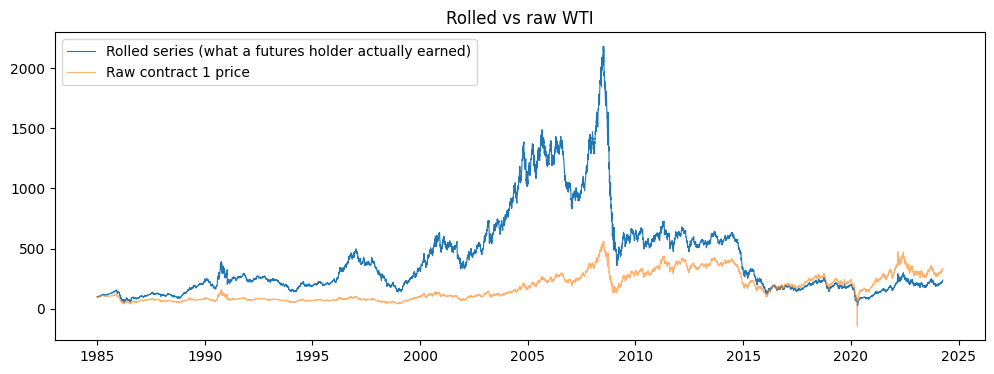


Tests 1-2 rerun:
  surprise vs release-day return corr: -0.141
  surprise vs next-week return corr:   -0.043
Test 3 rerun:
  1 month: t = 0.64, Sharpe = 0.20
  3 months: t = 0.33, Sharpe = 0.09
  12 months: t = -0.31, Sharpe = -0.13
Buy-and-hold Sharpe: 0.00


In [5]:
# ---------- 1. Pull daily prices for WTI futures contracts 1 and 2 from EIA ----------
def get_eia_daily(series_id, start='2004-01-01'):
    url = f'https://api.eia.gov/v2/seriesid/PET.{series_id}.D'
    rows, offset = [], 0
    while offset < 50000:   # API returns max 5000 rows per request, so page through
        r = requests.get(url, params={'api_key': API_KEY, 'start': start,
                                      'offset': offset, 'length': 5000})
        r.raise_for_status()
        batch = r.json()['response']['data']
        rows += batch
        if len(batch) < 5000:
            break
        offset += 5000
    d = pd.DataFrame(rows).drop_duplicates('period')
    s = pd.Series(pd.to_numeric(d['value'], errors='coerce').values,
                  index=pd.to_datetime(d['period']))
    return s.sort_index()

fut = pd.DataFrame({'c1': get_eia_daily('RCLC1'), 'c2': get_eia_daily('RCLC2')}).dropna()
print(f"Futures data: {fut.index[0].date()} to {fut.index[-1].date()}, {len(fut)} days")

# ---------- 2. Work out each contract's expiry date (NYMEX rule) ----------
# WTI stops trading 3 business days before the 25th of the month (4 if the 25th isn't a trading day)
dates = fut.index
expiries = []
for (y, m), _ in fut.groupby([dates.year, dates.month]):
    d25 = pd.Timestamp(y, m, 25)
    before = dates[dates < d25]
    if len(before) >= 4:
        expiries.append(before[-3] if d25 in dates else before[-4])

# ---------- 3. Build a properly rolled return series ----------
# Hold contract 1; 5 trading days before expiry, switch to contract 2 (like a real trader would)
n = len(dates)
idx = pd.Series(np.arange(n), index=dates)
in_window = np.zeros(n, bool)   # days we're holding contract 2
switch = np.zeros(n, bool)      # first day after expiry: EIA's "contract 1" is now our contract
for e in idx[expiries].values:
    in_window[max(e - 5, 0):e + 1] = True
    if e + 1 < n:
        switch[e + 1] = True

c1v, c2v = fut['c1'].values, fut['c2'].values
r = np.full(n, np.nan)
for t in range(1, n):
    if switch[t]:
        r[t] = c1v[t] / c2v[t - 1] - 1   # yesterday's contract 2 is today's contract 1
    elif in_window[t - 1]:
        r[t] = c2v[t] / c2v[t - 1] - 1   # holding contract 2 through expiry week
    else:
        r[t] = c1v[t] / c1v[t - 1] - 1   # normal day, holding contract 1
fut['ret'] = r
adj = 100 * (1 + fut['ret'].fillna(0)).cumprod()   # rolled price index, starts at 100
fut['carry'] = fut['c1'] / fut['c2'] - 1           # >0 = backwardation, <0 = contango

# ---------- 4. Sanity checks ----------
sw = np.where(switch)[0]
match = np.mean([abs(c1v[t] / c2v[t - 1] - 1) < abs(c1v[t] / c1v[t - 1] - 1) for t in sw])
print(f"Roll check: {match:.0%} of switch days look like genuine contract switches")
print(f"Largest daily move: rolled series {fut['ret'].abs().max():.1%}")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(adj.index, adj, lw=0.8, label='Rolled series (what a futures holder actually earned)')
ax.plot(fut.index, 100 * fut['c1'] / fut['c1'].iloc[0], lw=0.8, alpha=0.6, label='Raw contract 1 price')
ax.legend(); ax.set_title('Rolled vs raw WTI'); plt.show()

# ---------- 5. Rebuild the weekly table on clean prices ----------
pos = adj.index.searchsorted(df['release'])
keep = pos < len(adj)
df = df[keep].copy(); pos = pos[keep]
df['entry_price'] = adj.values[pos]
df['prev_price'] = adj.values[pos - 1]
df['carry'] = fut['carry'].values[pos]
df['fwd_return'] = df['entry_price'].shift(-1) / df['entry_price'] - 1
df['release_day_return'] = df['entry_price'] / df['prev_price'] - 1

# ---------- 6. Rerun Tests 1-3 on clean data ----------
exp = df.loc['2010':'2021'].dropna(subset=['surprise', 'fwd_return', 'release_day_return'])
print("\nTests 1-2 rerun:")
print(f"  surprise vs release-day return corr: {exp['surprise'].corr(exp['release_day_return']):.3f}")
print(f"  surprise vs next-week return corr:   {exp['surprise'].corr(exp['fwd_return']):.3f}")
print("Test 3 rerun:")
for weeks, label in [(4, '1 month'), (13, '3 months'), (52, '12 months')]:
    past = df['entry_price'] / df['entry_price'].shift(weeks) - 1
    d = pd.DataFrame({'s': (past > 0).astype(int), 'f': df['fwd_return']}).loc['2010':'2021'].dropna()
    t = stats.ttest_ind(d.f[d.s == 1], d.f[d.s == 0], equal_var=False).statistic
    strat = d.s * d.f
    print(f"  {label}: t = {t:.2f}, Sharpe = {strat.mean() / strat.std() * np.sqrt(52):.2f}")
bh = exp['fwd_return']
print(f"Buy-and-hold Sharpe: {bh.mean() / bh.std() * np.sqrt(52):.2f}")

Data fix: Replaced Yahoo CL=F with a rolled series built from EIA contract 1/2 prices (roll 5 days pre-expiry). EIA futures data ends 2024-04-05, so the holdout is now Jan 2022 – Apr 2024.
Tests 1–3 rerun on clean data: release-day corr −0.141; next-week corr −0.043; trend t-stats 0.64 / 0.33 / −0.31. Conclusions unchanged. Buy-and-hold Sharpe 2010–21: 0.00.

Sample extension (decided before running Test 4): Exploration period extended from 2010–2021 to 1990–2021 after Tests 1–3 found nothing, for statistical power (32 vs 12 years). 1990–2021 is the primary result; 2010–2021 is reported alongside as a consistency check. Tests 1–3 are rerun on the new sample. Holdout (2022 – Apr 2024) is still untouched.


In [6]:
# ---------- Rebuild weekly table using full EIA history (back to 1982) ----------
eia_full = pd.DataFrame({name: get_eia(sid) for name, sid in SERIES.items()})

df = eia_full.copy()
df['change'] = df['stocks'].diff()
df['year'] = df.index.isocalendar().year.astype(int)
df['week'] = df.index.isocalendar().week.astype(int)
pivot = df.pivot_table(index='year', columns='week', values='change')
norm = pivot.shift(1).rolling(5, min_periods=5).mean()
df['norm'] = [norm.at[y, w] if w in norm.columns else np.nan for y, w in zip(df['year'], df['week'])]
df['surprise'] = df['change'] - df['norm']
df['release'] = df.index + pd.Timedelta(days=5)

# Line up with the rolled futures series
pos = adj.index.searchsorted(df['release'])
keep = (pos > 0) & (pos < len(adj))
df = df[keep].copy(); pos = pos[keep]
df['entry_price'] = adj.values[pos]
df['prev_price'] = adj.values[pos - 1]
df['carry'] = fut['carry'].values[pos]   # >0 = backwardation at entry
df['fwd_return'] = df['entry_price'].shift(-1) / df['entry_price'] - 1
df['release_day_return'] = df['entry_price'] / df['prev_price'] - 1
for w in [4, 13, 52]:
    df[f'trend_{w}'] = df['entry_price'] / df['entry_price'].shift(w) - 1
print(f"Weekly table: {df.index[0].date()} to {df.index[-1].date()}, {len(df)} weeks")

# ---------- Reusable test: long when signal > 0, flat otherwise ----------
def sharpe(x):
    return x.mean() / x.std() * np.sqrt(52)

def test_long_flat(signal_col, start, end):
    d = df.loc[start:end, [signal_col, 'fwd_return']].dropna()
    s = (d[signal_col] > 0).astype(int)
    up, down = d.loc[s == 1, 'fwd_return'], d.loc[s == 0, 'fwd_return']
    t = stats.ttest_ind(up, down, equal_var=False).statistic
    return {'% long': round(100 * s.mean(), 1), 't-stat': round(t, 2),
            'Sharpe': round(sharpe(s * d['fwd_return']), 2)}

# ---------- Run everything on both periods ----------
for start, end, label in [('1990', '2021', 'PRIMARY: 1990-2021'),
                          ('2010', '2021', 'Consistency check: 2010-2021')]:
    e = df.loc[start:end].dropna(subset=['surprise', 'fwd_return', 'release_day_return'])
    print(f"\n===== {label} ({len(e)} weeks) =====")
    print(f"Test 1  surprise vs next-week return corr:   {e['surprise'].corr(e['fwd_return']):.3f}")
    print(f"Test 2  surprise vs release-day return corr: {e['surprise'].corr(e['release_day_return']):.3f}")
    rows = {f'Test 3  trend {w}w': test_long_flat(f'trend_{w}', start, end) for w in [4, 13, 52]}
    rows['Test 4  carry (backwardation)'] = test_long_flat('carry', start, end)
    print(pd.DataFrame(rows).T.to_string())
    print(f"Buy-and-hold Sharpe: {sharpe(e['fwd_return']):.2f}")


Weekly table: 1985-01-04 to 2024-03-29, 2048 weeks

===== PRIMARY: 1990-2021 (1664 weeks) =====
Test 1  surprise vs next-week return corr:   -0.034
Test 2  surprise vs release-day return corr: -0.138
                               % long  t-stat  Sharpe
Test 3  trend 4w                 53.6    2.23    0.50
Test 3  trend 13w                56.2    1.57    0.40
Test 3  trend 52w                53.0    1.05    0.30
Test 4  carry (backwardation)    38.9    2.36    0.48
Buy-and-hold Sharpe: 0.18

===== Consistency check: 2010-2021 (624 weeks) =====
Test 1  surprise vs next-week return corr:   -0.044
Test 2  surprise vs release-day return corr: -0.142
                               % long  t-stat  Sharpe
Test 3  trend 4w                 53.9    0.64    0.20
Test 3  trend 13w                54.5    0.33    0.09
Test 3  trend 52w                42.7   -0.31   -0.13
Test 4  carry (backwardation)    26.2    1.52    0.46
Buy-and-hold Sharpe: -0.00


Tests 1–4 on 1990–2021 (primary): release-day corr −0.138 (~5.6 s.e.); next-week corr −0.034. Trend t = 2.23 / 1.57 / 1.05. Carry t = 2.36, Sharpe 0.48 vs B&H 0.18. None clears the pre-set t ≈ 2.5 bar. Consistency (2010–21): carry same direction (Sharpe 0.46 vs 0.00, t = 1.52); trend inconsistent.

Strategy candidates (declared before testing):

A. Pure carry: long WTI at Wednesday close if contract 1 > contract 2 (backwardation), else flat. Hold one week.
B. Carry + inventory filter: as A, but also require the week’s inventory surprise ≤ 0 (draw at least as big as the seasonal norm).

Decision rule: compare both on 1990–2021 after costs. B goes forward only if its Sharpe beats A’s by more than 0.1; otherwise A goes forward, because it’s simpler. Whichever goes forward is the only one run on the holdout, once.

Costs: 0.05% per trade (each entry, exit and monthly roll while in a position); sensitivity tested at 0–0.2%.

Significance: block bootstrap (26-week blocks, 10,000 resamples) of the Sharpe difference vs buy-and-hold.

In [7]:
# ---------- Transaction costs: count futures rolls inside each holding week ----------
fi = pd.Series(np.arange(len(fut)), index=fut.index)
roll_days = fut.index[np.maximum(fi[expiries].values - 5, 0)]   # we roll 5 trading days pre-expiry
entry = adj.index[adj.index.searchsorted(df['release'])]
next_entry = pd.Series(entry, index=df.index).shift(-1)
df['rolls_in_week'] = [((roll_days > a) & (roll_days <= b)).sum() if pd.notna(b) else 0
                       for a, b in zip(entry, next_entry)]

def backtest(position, cost):
    """position: 1 = long, 0 = flat, decided at Wednesday close. cost: per trade, e.g. 0.0005 = 0.05%."""
    trades = position.diff().abs().fillna(position.iloc[0])     # entries and exits
    rolls = position * df.loc[position.index, 'rolls_in_week']  # rolls while holding
    return position * df.loc[position.index, 'fwd_return'] - cost * (trades + rolls)

def scorecard(r, position=None):
    wealth = (1 + r).cumprod()
    dd = wealth / wealth.cummax() - 1
    under = (dd < 0).astype(int)
    longest = (under.groupby((under == 0).cumsum()).cumsum()).max()
    out = {'Sharpe': sharpe(r),
           'Ann. return %': 100 * (wealth.iloc[-1] ** (52 / len(r)) - 1),
           'Ann. vol %': 100 * r.std() * np.sqrt(52),
           'Max drawdown %': 100 * dd.min(),
           'Longest drawdown (weeks)': longest}
    if position is not None:
        held = r[position == 1]
        out['% weeks long'] = 100 * position.mean()
        out['Hit rate % (weeks long)'] = 100 * (held > 0).mean()
        out['Trades'] = int(position.diff().abs().sum())
    return out

# ---------- The two declared strategies, 1990-2021 ----------
period = df.loc['1990':'2021'].dropna(subset=['fwd_return', 'carry', 'surprise'])
posA = (period['carry'] > 0).astype(int)                               # A: pure carry
posB = ((period['carry'] > 0) & (period['surprise'] <= 0)).astype(int) # B: carry + inventory filter
COST = 0.0005
rA, rB = backtest(posA, COST), backtest(posB, COST)
bh = period['fwd_return'] - COST * period['rolls_in_week']   # buy-and-hold pays roll costs too

table = pd.DataFrame({'A: pure carry': scorecard(rA, posA),
                      'B: carry + inventory': scorecard(rB, posB),
                      'Buy-and-hold': scorecard(bh)}).round(2)
print("===== 1990-2021, after 0.05% costs =====")
print(table.to_string())

print("\nCost sensitivity (Sharpe):")
for c in [0, 0.0005, 0.001, 0.002]:
    print(f"  {c*100:.2f}% per trade:  A = {sharpe(backtest(posA, c)):.2f},  B = {sharpe(backtest(posB, c)):.2f}")

# ---------- Block bootstrap: is the Sharpe improvement over buy-and-hold real? ----------
def block_bootstrap_pvalue(strat, bench, block=26, n_boot=10000, seed=42):
    rng = np.random.default_rng(seed)
    s, b = strat.values, bench.values
    n = len(s); n_blocks = int(np.ceil(n / block))
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        starts = rng.integers(0, n - block, n_blocks)
        ix = (starts[:, None] + np.arange(block)).ravel()[:n]
        diffs[i] = sharpe(pd.Series(s[ix])) - sharpe(pd.Series(b[ix]))
    return (diffs <= 0).mean(), np.percentile(diffs, [2.5, 97.5])

print("\nBlock bootstrap, Sharpe vs buy-and-hold:")
for name, r in [('A', rA), ('B', rB)]:
    p, ci = block_bootstrap_pvalue(r, bh)
    print(f"  {name}: Sharpe diff = {sharpe(r) - sharpe(bh):.2f}, "
          f"95% CI [{ci[0]:.2f}, {ci[1]:.2f}], p = {p:.3f}")

===== 1990-2021, after 0.05% costs =====
                          A: pure carry  B: carry + inventory  Buy-and-hold
Sharpe                             0.46                  0.59          0.17
Ann. return %                      7.63                  8.05         -0.98
Ann. vol %                        20.43                 14.92         37.92
Max drawdown %                   -49.73                -26.91        -98.36
Longest drawdown (weeks)         677.00                267.00        703.00
% weeks long                      39.00                 20.67           NaN
Hit rate % (weeks long)           56.86                 61.05           NaN
Trades                           136.00                358.00           NaN

Cost sensitivity (Sharpe):
  0.00% per trade:  A = 0.49,  B = 0.64
  0.05% per trade:  A = 0.46,  B = 0.59
  0.10% per trade:  A = 0.44,  B = 0.55
  0.20% per trade:  A = 0.40,  B = 0.46

Block bootstrap, Sharpe vs buy-and-hold:
  A: Sharpe diff = 0.30, 95% CI [-0.03, 0.59]

Strategy test, 1990–2021, 0.05% costs: A Sharpe 0.46, B Sharpe 0.59, buy-and-hold 0.17. Per the pre-declared rule (B beats A by more than 0.1), B goes forward. B: 8.05% annual return, 14.9% vol, −26.9% max drawdown, 61% hit rate, long 21% of weeks. Robust to costs (Sharpe 0.46 at 0.20%). Block bootstrap vs buy-and-hold: B p = 0.026 one-sided, 95% CI [−0.01, 0.79]. Moderate evidence; borderline after adjusting for two variants.

Holdout criteria (declared before running): B passes if its Sharpe after costs is above 0 and its max drawdown is no worse than the in-sample −26.9%. The holdout is only about 2.3 years, so it can catch a broken strategy but can’t confirm a good one.

In [8]:
hold = df.loc['2022':].dropna(subset=['fwd_return', 'carry', 'surprise'])
posH = ((hold['carry'] > 0) & (hold['surprise'] <= 0)).astype(int)
rH = backtest(posH, COST)
bhH = hold['fwd_return'] - COST * hold['rolls_in_week']

print(f"HOLDOUT: {hold.index[0].date()} to {hold.index[-1].date()}, {len(hold)} weeks")
print(pd.DataFrame({'B: carry + inventory': scorecard(rH, posH),
                    'Buy-and-hold': scorecard(bhH)}).round(2).to_string())

HOLDOUT: 2022-01-07 to 2024-03-22, 116 weeks
                          B: carry + inventory  Buy-and-hold
Sharpe                                   -0.05          0.42
Ann. return %                            -4.21          9.28
Ann. vol %                               24.28         42.04
Max drawdown %                          -28.84        -40.67
Longest drawdown (weeks)                 75.00         95.00
% weeks long                             38.79           NaN
Hit rate % (weeks long)                  55.56           NaN
Trades                                   45.00           NaN


Holdout (2022-01 → 2024-03, run once): B Sharpe −0.05 (B&H 0.42), max DD −28.8%. Fails both pre-declared criteria. Long 39% of weeks vs 21% in-sample. Strategy not modified after holdout.